> **Language & Quick Links**: [🇰🇷 한국어 (`notebooks/ko/stage4_agent_and_mcp_execution_ko.ipynb`)](../ko/stage4_agent_and_mcp_execution_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Methodology Guide](../../methodology/04_stage4_agent_and_mcp_en.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage4)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → **[▶ Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb)** → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# Stage 4. [Build Agent & Answer] 8-Tool Modular MCP Server, Slot Validation & 2-Pass AI FDE Agent Execution
## Step 4.1 8 MCP Tools & 2-Pass Agent Architecture Setup · Step 4.2 Deterministic Penalty Simulation & Guardrailed Answering

Stage 4 implements **Phase 6 (Agent & MCP Setup)** and **Phase 7 (Grounded Answering)**. To prevent LLM math errors or entity hallucinations, we combine **(1) Live BigQuery Catalog Slot Validation (`resolve_params`)**, **(2) the 8-Tool Modular MCP Server (`DomainMcpServer`) executing deterministic SQL and parameterized ISO GQL**, and **(3) the 4-Step, 2-Pass Gemini (`gemini-3.8-flash`) Reasoning Engine (`AiFdeAgentEngine`)**, verifying both `GROUNDED` answers and boundary guardrails (`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`).

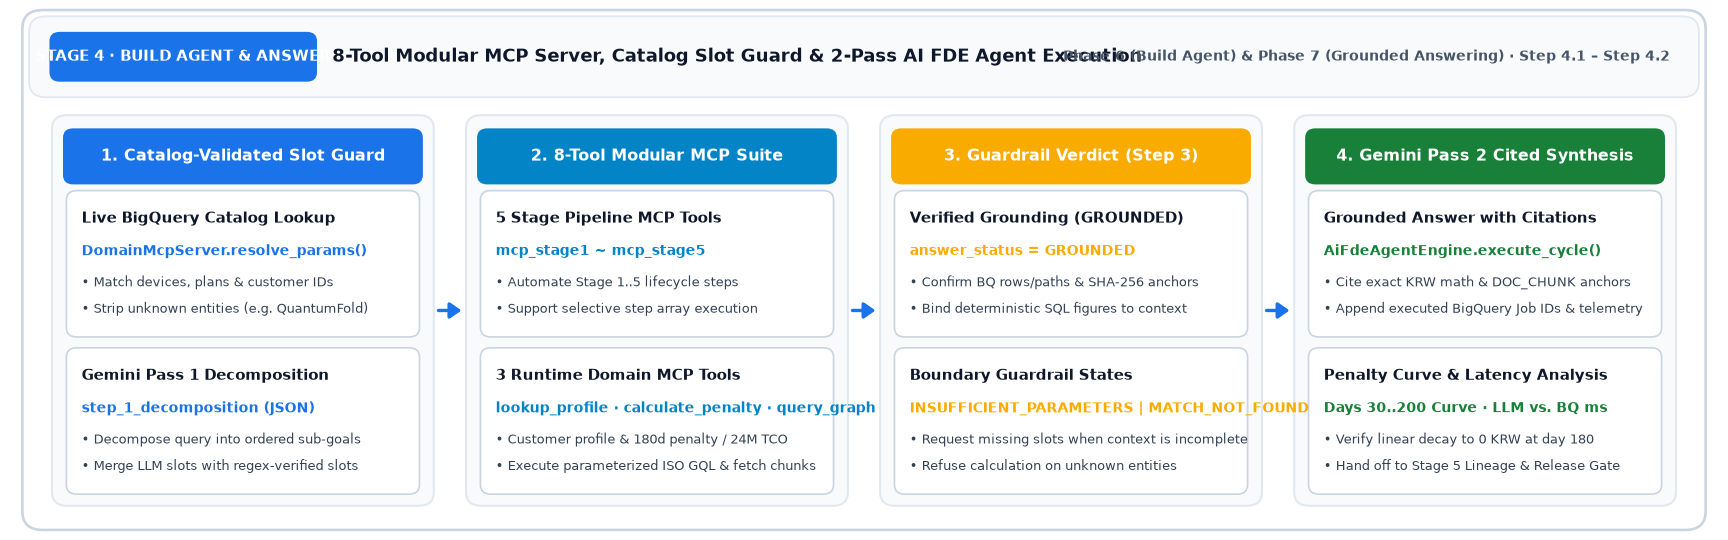


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 6a: Agent & MCP Architecture Setup] 2-Pass Orchestration Blueprint, 8-Tool MCP Catalog & `mcp_stage4_agent_orchestration`


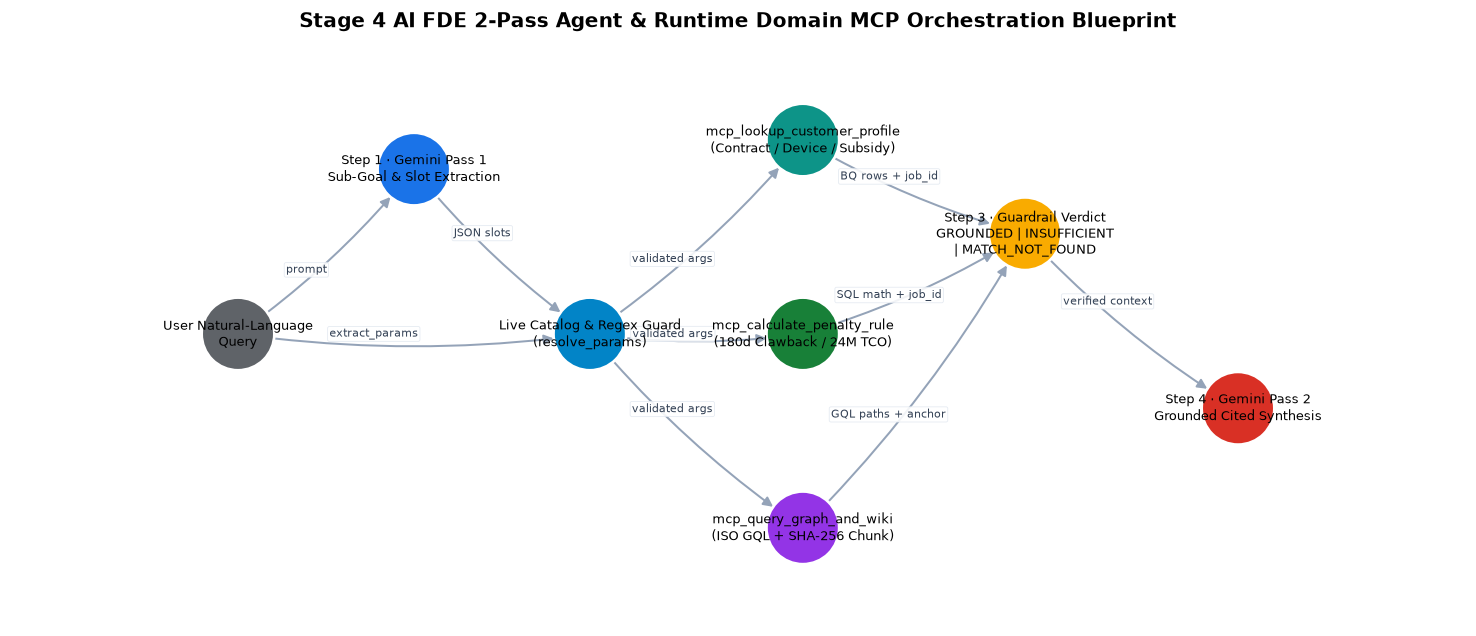

,name,stage,category,steps,spec_origin,description_en
0,mcp_stage1_asset_discovery,STAGE 1,stage_pipeline,"[profile_tables, scan_guides, prune_noise, tag_pii_governance]",GCP_NATIVE,Stage 1 live BigQuery table profiling and customer ID de-identification check
1,mcp_stage2_wiki_and_semantic,STAGE 2,stage_pipeline,"[compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges]",CUSTOM_EXTENSION,Stage 2 GCS wiki object listing and BigQuery chunk/rule anchor lookup
2,mcp_stage3_property_graph,STAGE 3,stage_pipeline,"[promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates]",GCP_NATIVE,Stage 3 node-table duplicate-key check and Property Graph GQL path count
3,mcp_stage4_agent_orchestration,STAGE 4,stage_pipeline,"[decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors]",CUSTOM_EXTENSION,Stage 4 domain rules and grounding chunks used by the agent (BigQuery)
4,mcp_stage5_lineage_and_eval,STAGE 5,stage_pipeline,"[build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures]",CUSTOM_EXTENSION,Stage 5 contract→device/plan/subsidy→rule→chunk lineage join and latest validation sum...
5,mcp_lookup_customer_profile,RUNTIME,runtime_domain,"[lookup_contract, lookup_device_price, lookup_subsidy_policy]",CUSTOM_EXTENSION,"Customer contract, device price and subsidy lookup (returns 0 rows + live catalog on m..."
6,mcp_calculate_penalty_rule,RUNTIME,runtime_domain,"[check_exemptions, compute_180d_prorated_clawback, compare_24m_tco]",CUSTOM_EXTENSION,"180-day prorated penalty, exemption and 24-month TCO computed in BigQuery SQL"
7,mcp_query_graph_and_wiki,RUNTIME,runtime_domain,"[traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema]",GCP_NATIVE,Property Graph GRAPH_TABLE multi-hop traversal and grounding chunk retrieval


**`mcp_stage4_agent_orchestration`** · status `SUCCESS` · steps `decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors` · BigQuery jobs 1 (432 ms)

도메인 규칙 4개와 근거 청크 앵커 조회

- `job_SPCoWJp7m7Ub_vAwza15_8eLmKaf`

,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,anchor
0,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee < 45000,penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...,DOC_CHUNK_003,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...,DOC_CHUNK_001,anchor_a52e1a72869f
2,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...,DOC_CHUNK_005,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')",penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE),DOC_CHUNK_004,anchor_269d9c42e05c


In [2]:
H.draw_agent_architecture()
H.show(pd.DataFrame(server.get_tool_catalog()), ["name", "stage", "category", "steps", "spec_origin", "description" if H.LANG == "ko" else "description_en"])
res_s4 = server.execute_tool("mcp_stage4_agent_orchestration", {"steps": ["decompose_subgoals", "dispatch_domain_mcps", "verify_grounding_anchors"]})
H.show_tool(res_s4, "active_rules")


### 2. [Phase 6b: Catalog-Validated Slot Resolution (`resolve_params`)] Extracting Parameters & Stripping Unregistered Entities


In [3]:
sample_queries = [
    "CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",
    "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?",
    "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",
    "방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",
]
slot_rows = []
for q in sample_queries:
    resolved = server.resolve_params({"query": q})
    slot_rows.append({"query": q, **{k: v for k, v in resolved.items()}})
H.show(pd.DataFrame(slot_rows))


,query,customer_id,device_name,storage_gb,plan_name,monthly_fee_krw,target_plan_name,target_monthly_fee_krw,elapsed_days
0,"CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",CUST_DEMO_001,None,NaN,5G Light (Below Baseline),NaN,None,37000.0,120.0
1,AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?,NaN,None,256.0,NaN,NaN,None,NaN,NaN
2,"CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",NaN,None,NaN,NaN,99000.0,None,NaN,NaN
3,"방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",NaN,None,NaN,NaN,37000.0,None,NaN,NaN


### 3. [Phase 6c: Direct Execution of 3 Runtime Domain MCP Tools] Customer Profile, Penalty/24M TCO Math, Graph Traversal (`executed_gql` + Bound Variables) & 180-Day Penalty Curve


**`mcp_lookup_customer_profile`** · status `SUCCESS` · steps `lookup_contract, lookup_device_price, lookup_subsidy_policy` · BigQuery jobs 1 (452 ms)

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | Validated catalog slot via DomainMcpServer.resolve_params() |

- `job_Y_za2TuxAMGgYPWla1hbeocbuHY-`

,customer_id,device_name,plan_name,monthly_fee_krw,factory_price_krw,total_subsidy_krw,net_installment_principal_krw,grounded_chunk_id
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,517500,1180900,DOC_CHUNK_001


**`mcp_calculate_penalty_rule`** · status `SUCCESS` · steps `check_exemptions, compute_180d_prorated_clawback, compare_24m_tco` · BigQuery jobs 2 (792 ms)

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | Validated catalog slot via DomainMcpServer.resolve_params() |
| `target_monthly_fee_krw` | `37000` | Validated catalog slot via DomainMcpServer.resolve_params() |
| `elapsed_days` | `120` | Validated catalog slot via DomainMcpServer.resolve_params() |

- `job_j02PxZDG6Wg0Y43vzxbmbuVmmewZ`
- `job_x6kqJg2q-daS2VOASGf1wDIY78kO`

,customer_id,plan_name,target_plan_name,elapsed_days,penalty_status,penalty_krw,public_subsidy_24m_tco_krw,selective_24m_tco_krw,tco_recommendation,grounded_chunk_id
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),120,PRORATED_PENALTY,100000,3220900,3228400,PUBLIC_SUBSIDY,DOC_CHUNK_003


**`mcp_query_graph_and_wiki`** · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · BigQuery jobs 1 (451 ms)

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | Validated catalog slot via DomainMcpServer.resolve_params() |

**Executed GRAPH_TABLE / ISO GQL Statement**
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- `job_E3PGZSyBO4tjQuFVR0RrtDhkA82a`

,customer_id,device_name,plan_name,rule_id,relation_label_ko,source_chunk_id,anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,180일 기준선 유지 의무 적용,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,anchor_4fbaf9c5cba8


,elapsed_days,penalty_krw,penalty_status,applied_rule_id,public_24m_tco_krw,selective_24m_tco_krw,bq_job_id
0,30,250000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_uaNTf0S8Z8Sfu1L1fKrDaj_hY6bu
1,60,200000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_vNDGU0NtXG5hrzFHdlUVHIUNvxuE
2,90,150000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_Y3b2aM8Q38CTd3lqyrGVCpepOJLB
3,120,100000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_Gbop1yaQVT4OCckGzf8fUwuBsFtL
4,150,50000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_yuT76lnWJ8QZqNBk9atxjSpTmJ6F
5,179,1667,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_QzvR69oZ7tGKeOcvsL9Rsnkk0oIB
6,180,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_6ve1kqkYdk3YxZ55jb-PHBsyWmG2
7,200,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_DqqOJYrlTVgivqHLUEV0cn1wVf4K


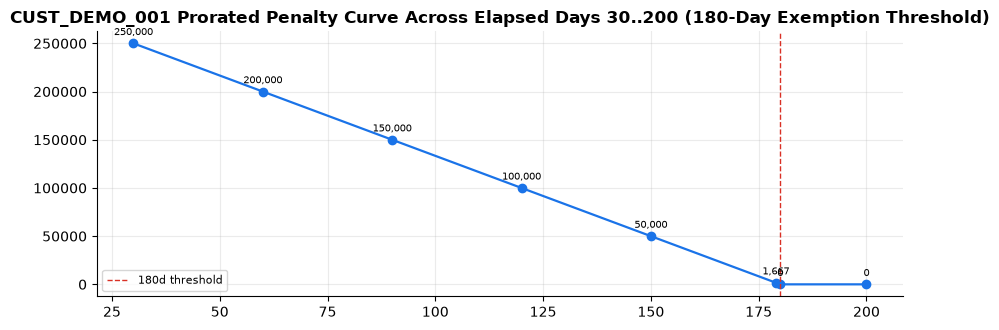

In [4]:
r_prof = server.execute_tool("mcp_lookup_customer_profile", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_prof, "matched_rows", ["customer_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "total_subsidy_krw", "net_installment_principal_krw", "grounded_chunk_id"])

r_pen = server.execute_tool("mcp_calculate_penalty_rule", {"customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120})
H.show_tool(r_pen, "calculations", ["customer_id", "plan_name", "target_plan_name", "elapsed_days", "penalty_status", "penalty_krw", "public_subsidy_24m_tco_krw", "selective_24m_tco_krw", "tco_recommendation", "grounded_chunk_id"])

r_gql = server.execute_tool("mcp_query_graph_and_wiki", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_gql, "matched_graph_paths", ["customer_id", "device_name", "plan_name", "rule_id", "relation_label_ko", "source_chunk_id", "anchor"])

df_curve = H.penalty_curve(server, "CUST_DEMO_001", 37000, [30, 60, 90, 120, 150, 179, 180, 200])
H.show(df_curve)
H.line(df_curve, "elapsed_days", "penalty_krw",
       H.t("CUST_DEMO_001 경과일(30~200일)별 차액정산 위약금 시뮬레이션 곡선 (180일 면제 경계)",
           "CUST_DEMO_001 Prorated Penalty Curve Across Elapsed Days 30..200 (180-Day Exemption Threshold)"),
       vline=180, vline_label="180d threshold")


### 4. [Phase 7: End-to-End 2-Pass Agent Answering] Golden CQs (`GROUNDED`) & Boundary Guardrails (`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`)


#### CQ-01 (Subsidy & Net Price)
**Q.** AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"storage_gb": 256, "device_mention": "AlphaPhone 16 Pro 256GB", "plan_mention": "5G Signature 115"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 5 | 399 | `job_h3Oa6i-gTNLaQdj3zkcu0trWlC0U` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 413 | `job_aAU28IIqGXSrbFlPjEZIoZd0M5t2` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"storage_gb": 256, "device_mention": "AlphaPhone 16 Pro 256GB", "plan_mention": "5G Signature 115"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 8,367 tokens, LLM 22,169 ms / total 23.37 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### 결론
> 요청 조건과 일치하는 데이터가 BigQuery(`seanjung-poc.starter_ontology_dw`)에 없습니다(0건). 
>
> 요청하신 **AlphaPhone 16 Pro 256GB** 단말기 및 **5G Signature 115** 요금제는 데이터베이스에 등록되어 있지 않아 공시지원금, 유통망 추가지원금 상한, 총 지원금 및 실구매가를 산출할 수 없습니다.
>
> ---
>
> ### 근거 데이터 (BigQuery)
>
> 현재 BigQuery에 저장된 256GB 단말기 및 관련 요금제 정책은 다음과 같습니다.
>
> #### 참고 (질문과 다른 조건의 데이터)
>
> 1. **iPhone 16 Pro 256GB** (`DEV-IP16P-256`, 출고가: 1,700,000원)
>    - **5G Premier Essential (월 85,000원)** (정책 ID: `POL-2026-005`):
>      - 공시지원금(기본 지원금): 400,000원
>      - 유통망 추가지원금 상한: 60,000원
>      - 총 지원금: 460,000원
>      - 실구매가(순 할부원금): 1,240,000원
>
> 2. **Galaxy S26 Ultra 256GB** (`DEV-S26U-256`, 출고가: 1,698,400원)
>    - **5G Premier Super (월 130,000원)** (`POL-2026-001`): 총 지원금 575,000원 (기본 500,000원 + 추가 75,000원), 실구매가 1,123,400원
>    - **5G Premier Essential (월 85,000원)** (`POL-2026-002`): 총 지원금 517,500원 (기본 450,000원 + 추가 67,500원), 실구매가 1,180,900원
>    - **5G Slim (Baseline Threshold) (월 45,000원)** (`POL-2026-003`): 총 지원금 345,000원 (기본 300,000원 + 추가 45,000원), 실구매가 1,353,400원
>    - **5G Light (Below Baseline) (월 37,000원)** (`POL-2026-004`): 총 지원금 172,500원 (

#### CQ-02 (120d Prorated Penalty)
**Q.** CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "월 37,000원 요금제(5G Lite 37)"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 404 | `job_-gvz3WMjcfJLB1seB4PQmM8NLEhE` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 932 | `job_oaULjrmT4s2l9fMZ9vLkdp3UhQkA`, `job_eMCxtGYcjHEIrkVDsmCrvPkDuSZq` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 446 | `job_1eny9jFnuqKE8HLV_m4VTKDhbuZV` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "월 37,000원 요금제(5G Lite 37)"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,625 tokens, LLM 10,928 ms / total 12.71 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### **결론**
> CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Light (Below Baseline))로 하향 변경할 경우 발생하는 차액정산 위약금은 **100,000원**입니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
> - **고객 ID / 계약 ID**: CUST_DEMO_001 / CONTRACT_DEMO_101
> - **약정 유형**: 공시지원금 (PUBLIC_SUBSIDY)
> - **현재 이용 요금제**: 5G Premier Essential (월 85,000원)
> - **기본 공시지원금**: 450,000원
> - **변경 대상 요금제**: 5G Light (Below Baseline) (월 37,000원)
> - **변경 대상 기본 공시지원금**: 150,000원
> - **기준선(Baseline) 요금**: 월 45,000원
> - **의무 유지 기간 / 경과 일수**: 180일 / 120일 (잔여 60일)
> - **위약금 산식 및 계산**:
>   $$\text{위약금} = (\text{초기 기본지원금} - \text{변경 요금제 기본지원금}) \times \frac{180 - \text{유지일수}}{180}$$
>   $$\text{위약금} = (450,000\text{원} - 150,000\text{원}) \times \frac{180 - 120}{180} = 300,000\text{원} \times \frac{60}{180} = 100,000\text{원}$$
>
> ---
>
> ### **규칙·원문 근거**
> - **적용 규칙**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>   - **조건식**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   - **계산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>   - **근거 청크 ID**: 
>     - `DOC_CHUNK_003` (anchor: `anchor_47971ec8e4d8`)
>     - `DOC_CHUNK_002` (Baseline Plan Commitment (Six-Plan Rule), anchor: `anchor_3003b683cea0`)
>
> ---
>
> ### **실행 정보**
> - **BigQuery Job ID**:
>   - 고객 프로필 조회: `job_-gvz3WMjcfJLB1seB4PQmM8NLEhE`
>   - 위약금 규칙 계산: `job_oaULjrmT4s2l9fMZ9vLkdp3UhQkA`, `job_eMCxtGYcjHEIrkVDsmCrvPkDuSZq`
>   - 온톨로지 그래프 탐색: `job_1eny9jFnuqKE8HLV_m4VTKDhbuZV`

#### CQ-03 (Welfare Exemption)
**Q.** 국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "하위 요금제"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 445 | `job_cP4lDt2tTiMHRb4U6pZ6ydoLYOyx` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 493 | `job_XrK0hQVQcxa5wjQvVyV3_7FNnpLG` |
| 3 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,048 | `job_ujGu7P9Ouh2zrp97abypsh4ZqdLX`, `job_1E2w2MQsMbWhXmtZBf1wR8XHr7uQ` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "하위 요금제"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_002'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,772 tokens, LLM 12,966 ms / total 14.95 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### **결론**
> **위약금 면제 대상에 해당하지 않습니다.**
>
> 고객 `CUST_DEMO_002`의 실제 데이터베이스상 복지 자격 상태(`welfare_status`)는 **`NONE`**으로 등록되어 있으며, 특례 규칙상 면제 대상(`SENIOR_EXEMPT`, `MILITARY_PAUSE_ELIGIBLE`)에 포함되지 않습니다. 
>
> 따라서 질문하신 유지 기간 95일(180일 미만) 시점에서 변경하려는 하위 요금제의 월정액이 기준선(45,000원) 미만일 경우 차액위약금이 부과됩니다. (단, 변경 대상 요금제(`target_plan_name`)가 특정되지 않아 정확한 위약금 액수는 산정되지 않았습니다: `penalty_status: TARGET_PLAN_NOT_RESOLVED`.)
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> * **고객 및 계약 정보 (`CUST_DEMO_002` / `CONTRACT_DEMO_102`)**
>   * 고객 세그먼트: `General_Standard` (연령대: `30s-40s`)
>   * 복지 감면 등록 상태 (`welfare_status`): **`NONE`**
>   * 약정 유형: `PUBLIC_SUBSIDY` (공시지원금 약정, 24개월)
>   * 기기명: Galaxy S26 Ultra 256GB (`DEV-S26U-256`, 출고가 1,698,400원)
>   * 현재 요금제: 5G Premier Super (`PLAN-5G-130`, 월정액 130,000원)
>   * 지급 공시지원금 합계: 575,000원 (기본 공시지원금 500,000원 + 추가지원금 75,000원)
>   * 의무유지 기준일수: 180일
>   * 기준 월정액 (`baseline_fee_krw`): 45,000원
>
> ---
>
> ### **규칙·원문 근거**
>
> 1. **복지 위약금 면제 특례 규칙 (`RULE_WELFARE_EXEMPT`, 청크 ID: `DOC_CHUNK_004`)**
>    * **조건식**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>    * **내용**: 만 65세 이상 시니어 복지 특례(`SENIOR_EXEMPT`) 대상자가 시니어/복지 요금제로 전환 시 등에 한해 180일 이내라도 위약금을 면제함. 
>    * **적용 결과**: 고객의 `welfare_status`가 `NONE`이므로 면제 조건 미충족.
>
> 2. **180일 의무유지 및 차액정산 규칙 (`RULE_SIX_PLAN_180D`, 청크 ID: `DOC_CHUNK_002`, `DOC_CHUNK_003`)**
>    * **조건식**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>    * **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>    * **내용**: 개통 후 180일 이내에 월정액 45,000원 미만 요금제로 하향 변경 시 일할 차액위약금이 부과됩니다.
>
> ---
>
> ### **실행 정보**
> * **BigQuery Job ID**:
>   * 고객 프로필 조회: `job_cP4lDt2tTiMHRb4U6pZ6ydoLYOyx`
>   * 그래프 및 지식 검색: `job_XrK0hQVQcxa5wjQvVyV3_7FNnpLG`
>   * 위약금 및 규칙 계산: `job_ujGu7P9Ouh2zrp97abypsh4ZqdLX`, `job_1E2w2MQsMbWhXmtZBf1wR8XHr7uQ`

#### BC-PARAM (Missing Customer/Device)
**Q.** 방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 465 | `job_vfcC2Z0GCX1rTQ_tbeb7Q3BatffB` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 7,139 tokens, LLM 22,508 ms / total 22.97 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### 결론
> 개통 직후(경과일수 0일 가정) 5G 기준선 요금제(월 45,000원) 미만인 **5G Light (Below Baseline, 월 37,000원)** 요금제로 하향 변경할 경우, 180일 의무유지 기준선 위반에 따라 **공시지원금 차액정산금(위약금)**이 전액 발생합니다.
>
> 정확한 위약금은 **개통하신 단말기** 및 **최초 가입 요금제**에 따라 다르며, 시스템에 등록된 단말기(`Galaxy S26 Ultra 256GB`) 기준 계산 금액은 아래와 같습니다:
> - **5G Premier Super (월 130,000원)**에서 변경 시: **402,500원**
> - **5G Premier Essential (월 85,000원)**에서 변경 시: **345,000원**
> - **5G Slim (월 45,000원)**에서 변경 시: **172,500원**
>
> ---
>
> ### 근거 데이터 (BigQuery)
>
> #### 1. 위약금 계산 산식
> $$\text{위약금} = (\text{최초 지급 공시지원금} - \text{하향 요금제 공시지원금}) \times \frac{180 - \text{경과일수}}{180}$$
> *(방금 개통한 경우 경과일수 = 0일 적용)*
>
> #### 2. Galaxy S26 Ultra 256GB 공시지원금 현황 및 차액정산
> * 하향 대상 요금제 지원금: **5G Light (Below Baseline)** = **172,500원** (`POL-2026-004`)
>
> | 최초 가입 요금제 (월정액) | 최초 지원금 | 하향 지원금 | 계산식 (경과일수 0일) | 발생 위약금 | 정책 ID |
> | :--- | :---: | :---: | :--- | :---: | :---: |
> | **5G Premier Super** (130,000원) | 575,000원 | 172,500원 | $(575,000 - 172,500) \times \frac{180}{180}$ | **402,500원** | `POL-2026-001` |
> | **5G Premier Essential** (85,000원) | 517,500원 | 172,500원 | $(517,500 - 172,500) \times \frac{180}{180}$ | **345,000원** | `POL-2026-002` |
> | **5G Slim (Baseline)** (45,000원) | 345,000원 | 172,500원 | $(345,000 - 172,500) \times \frac{180}{180}$ | **172,500원** | `POL-2026-003` |
>
> *(참고: iPhone 16 Pro 256GB의 경우 `5G Premier Essential` 기준 공시지원금은 460,000원(`POL-2026-005`)입니다.)*
>
> ---
>
> ### 규칙·원문 근거
> * **RULE_SIX_PLAN_180D (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)**
>   * **DOC_CHUNK_002** (*Baseline Plan Commitment (Six-Plan Rule)*, `anchor_3003b683cea0`): 공시지원금을 받은 가입자는 개통일로부터 180일 동안 기준 요금제(5G 월 45,000원) 이상을 유지해야 하며, 미만 하향 시 일할 차액정산금이 부과됩니다.
>   * **DOC_CHUNK_003** (*Penalty Math Formula*, `anchor_47971ec8e4d8`): 차액정산금 산식 규정 `Penalty = (Initial Granted Subsidy - Lower Tier Subsidy) * (180 - Elapsed Days) / 180`. 경과일수 180일 이상 시 위약금은 0원입니다.
> * **RULE_WELFARE_EXEMPT (시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례)**
>   * **DOC_CHUNK_004** (*Statutory Penalty Exemptions*, `anchor_269d9c42e05c`): 시니어(만 65세 이상) 및 복지 요금

#### BC-NOTFOUND (Unknown Entity)
**Q.** CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요.

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"device_mention": "QuantumFold 99"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 7 | 465 | `job_klRSoTi0uV-5QzK4MZJkW5bBm_Qw` |
| 2 | `mcp_calculate_penalty_rule` | `INSUFFICIENT_PARAMETERS` | - | 453 | `job__aqHb5dsI5opNtcu5nIBlGFeiqKF` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 628 | `job_hs5cX5rr2AVmMyVzkaGAIoHn1N39` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"device_mention": "QuantumFold 99"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=INSUFFICIENT_PARAMETERS` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 10,609 tokens, LLM 16,630 ms / total 18.18 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### **결론**
> 요청 조건(고객 ID: `CUST_NOT_EXIST_999`, 단말기: `QuantumFold 99`)과 일치하는 데이터가 BigQuery(`seanjung-poc.starter_ontology_dw`)에 존재하지 않으며(0건), 위약금 계산을 위한 필수 파라미터가 부족하여 위약금을 산출할 수 없습니다 (`INSUFFICIENT_PARAMETERS`).
>
> 위약금 계산을 위해서는 다음 정보가 추가로 필요합니다:
> - **부족한 파라미터 (missing_slots)**:
>   1. `customer_id 또는 단말기(+가입 요금제)`
>   2. `개통 후 경과일수`
>   3. `변경 희망 요금제`
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> #### 1. 온톨로지 DW 내 실제 조회 가능한 단말기 및 요금제 현황 (참고: 질문과 다른 조건)
> 현재 시스템에 등록되어 조회가 가능한 단말기 및 지원금 정책 데이터는 다음과 같습니다:
>
> - **Galaxy S26 Ultra 256GB** (출고가: 1,698,400원)
>   - 요금제 `5G Premier Super` (월 130,000원): 기본 지원금 500,000원, 추가지원금 75,000원, 총 지원금 575,000원 (실구매 원금: 1,123,400원)
>   - 요금제 `5G Premier Essential` (월 85,000원): 기본 지원금 450,000원, 추가지원금 67,500원, 총 지원금 517,500원 (실구매 원금: 1,180,900원)
>   - 요금제 `5G Slim (Baseline Threshold)` (월 45,000원): 기본 지원금 300,000원, 추가지원금 45,000원, 총 지원금 345,000원 (실구매 원금: 1,353,400원)
>   - 요금제 `5G Light (Below Baseline)` (월 37,000원): 기본 지원금 150,000원, 추가지원금 22,500원, 총 지원금 172,500원 (실구매 원금: 1,525,900원)
> - **Galaxy S26 Ultra 512GB** (출고가: 1,841,400원, 정책 미매핑)
> - **iPhone 16 Pro 256GB** (출고가: 1,700,000원)
>   - 요금제 `5G Premier Essential` (월 85,000원): 기본 지원금 400,000원, 추가지원금 60,000원, 총 지원금 460,000원 (실구매 원금: 1,240,000원)
> - **iPhone 16 Pro 512GB** (출고가: 2,000,000원, 정책 미매핑)
>
> ---
>
> ### **규칙·원문 근거**
>
> 요금제 변경 시 적용되는 도메인 위약금 산정 규칙은 다음과 같습니다:
>
> - **규칙 ID**: `RULE_SIX_PLAN_180D`
>   - **규칙명**: 180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙
>   - **적용 조건**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   - **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>   - **설명**: 개통 후 180일 이내에 월정액 45,000원 미만 요금제로 하향 변경 시, 기본 공시지원금 차액에 잔여일수 비율((180-유지일수)/180)을 곱한 일할 위약금이 부과됩니다. 180일 경과 시 위약금은 0원입니다.
>   - **근거 청크 ID**: `DOC_CHUNK_002` (anchor: `anchor_3003b683cea0`), `DOC_CHUNK_003` (anchor: `anchor_47971ec8e4d8`)
>
> - **규칙 ID**: `RULE_WELFARE_EXEMPT`
>   - **규칙명**: 시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례
>   - **적용 조건**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>   - **산식**: `penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)`
>   - **설명**: 만 65세 이상 시니어 복지 특례 대상자가 시니어/복지 요금제로 전환 시 180일 이내라도 차액정산 위약금을 100% 면제(0원)합니다.
>   - **근거 청크 ID**: `DOC_CHUNK_004` (anchor: `anchor_269d9c42e05c`)
>
> ---
>
> ### **실행 정보**
> - **고객 프로필 조회 Job ID**: `job_klRSoTi0uV-5QzK4MZJkW5bBm_Qw` (소요 시간: 464.85 ms)
> - **위약금 계산 규칙 Job ID**: `job__aqHb5dsI5opNtcu5nIBlGFeiqKF` (소요 시간: 452.56 ms)
> - **지식 그래프 및 규정 조회 Job ID**: `job_hs5cX5rr2AVmMyVzkaGAIoHn1N39` (소요 시간: 627.58 ms)

,id,answer_status,tools,bq_jobs,tokens,llm_ms,bq_ms,total_s
0,CQ-01,GROUNDED,lookup_customer_profile > query_graph_and_wiki,3,8367,22169,812,23.37
1,CQ-02,GROUNDED,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,5,6625,10928,1782,12.71
2,CQ-03,GROUNDED,lookup_customer_profile > query_graph_and_wiki > calculate_penalty_rule,5,6772,12966,1986,14.95
3,BC-PARAM,GROUNDED,query_graph_and_wiki,2,7139,22508,465,22.97
4,BC-NOTFOUND,INSUFFICIENT_PARAMETERS,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,4,10609,16630,1545,18.18


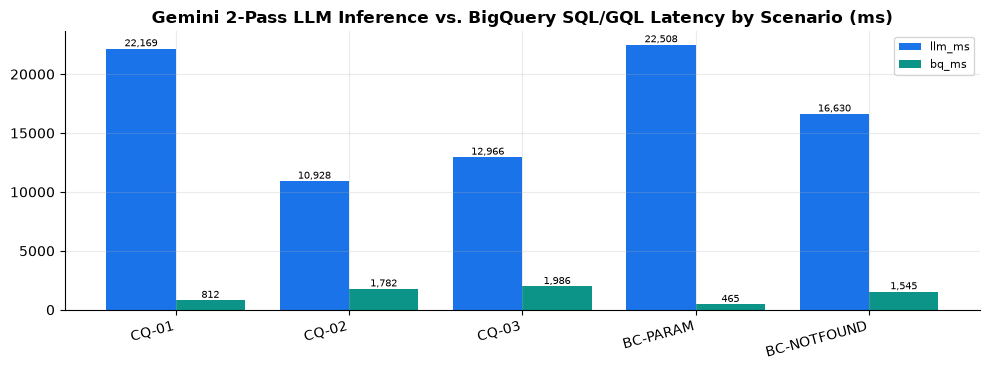

In [5]:
prompts = [
    ("CQ-01 (Subsidy & Net Price)", "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?"),
    ("CQ-02 (120d Prorated Penalty)", "CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?"),
    ("CQ-03 (Welfare Exemption)", "국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?"),
    ("BC-PARAM (Missing Customer/Device)", "방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?"),
    ("BC-NOTFOUND (Unknown Entity)", "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요."),
]
runs = []
for qid, q in prompts:
    res = agent.execute_cycle(q)
    H.show_agent(res, title=qid)
    runs.append(H.agent_row(res, qid.split()[0]))
df_runs = pd.DataFrame(runs)
H.show(df_runs)
H.grouped_bar(df_runs, "id", ["llm_ms", "bq_ms"],
              H.t("질의 시나리오별 Gemini 2-Pass 추론 시간 vs BigQuery SQL/GQL 실행 시간 (ms)",
                  "Gemini 2-Pass LLM Inference vs. BigQuery SQL/GQL Latency by Scenario (ms)"))


### Q&A
- **Q.** How does the AI FDE Agent prevent penalty calculation errors and hallucinated devices or customers?
  - **A.** `resolve_params()` validates extracted slots against the live BigQuery catalog (`get_live_catalog()`), delegates all arithmetic to deterministic BigQuery SQL inside `mcp_calculate_penalty_rule`, and enforces explicit `INSUFFICIENT_PARAMETERS` and `MATCH_NOT_FOUND` guardrail states.

### Data Analysis Key Findings
- Across elapsed days 30..200 for `CUST_DEMO_001`, the prorated penalty decreases linearly from `250,000 KRW` (day 30) to `100,000 KRW` (day 120) and `1,667 KRW` (day 179), dropping to `0 KRW` (`EXEMPT_RETENTION_COMPLETED`) at day 180.
- All Golden CQs (`CQ-01`–`CQ-03`) returned `GROUNDED` responses citing exact SQL-computed figures (`575,000 KRW`, `100,000 KRW`, `0 KRW`), SHA-256 chunk anchors, and BigQuery Job IDs.
- Missing-slot queries (`BC-PARAM`) triggered `INSUFFICIENT_PARAMETERS` and unknown-entity queries (`BC-NOTFOUND`) triggered `MATCH_NOT_FOUND` with 0 hallucinated figures.

### Insights or Next Steps
- Proceed to the final `Stage 5 (Verify & Evaluate)` notebook to inspect the 4-Tier end-to-end data lineage graph, Golden CQ re-verification, and the 50-trial boundary benchmark release gate.

---
> **Next Navigation**: [⬅️ Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb) ｜ [🌐 한국어 버전](../ko/stage4_agent_and_mcp_execution_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/04_stage4_agent_and_mcp_en.md)
